# 01 · Problema, dados e exploração

**Objetivo:** prever, ao fim de um dia, a **temperatura máxima de amanhã** (°C) em Jaraguá do Sul (SC).

**Quem usaria:** produtores rurais (estresse térmico em animais e lavouras, horário de pulverização), Defesa Civil e
Secretaria de Saúde (alertas de calor para idosos e crianças), escolas e empresas (atividades ao ar livre, climatização),
comércio (bebidas, ventiladores) e a população em geral.

**Fonte dos dados:** [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api),
reanálise **ERA5** do Copernicus (licença CC BY 4.0), ponto de grade -26,49; -49,07, série diária desde 01/01/2010.
O arquivo `data/raw/jaragua_diario.csv` foi baixado com `python -m src.dados`.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src import config, features, modelagem

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
config.FIGURAS.mkdir(parents=True, exist_ok=True)

In [2]:
bruto = features.carregar()
print(f"{len(bruto)} dias, de {bruto.data.min():%d/%m/%Y} a {bruto.data.max():%d/%m/%Y}")
bruto.head()

6165 dias, de 01/01/2010 a 17/11/2026


,data,tmax,tmin,tmed,umidade,orvalho,pressao,nuvens,vento_max,rajada,vento_dir,chuva,horas_chuva,radiacao,evapotranspiracao
0,2010-01-01,25.6,19.8,22.8,79.0,18.7,1014.2,81.0,15.7,36.7,140.0,0.3,2.0,19.33,3.92
1,2010-01-02,29.9,20.2,25.0,79.0,20.9,1012.6,40.0,12.6,30.6,103.0,0.0,0.0,25.27,5.12
2,2010-01-03,28.0,21.6,24.7,87.0,22.2,1014.9,78.0,10.9,28.1,101.0,0.6,3.0,15.51,3.18
3,2010-01-04,28.3,23.6,25.5,89.0,23.5,1013.9,99.0,8.3,22.3,59.0,5.6,14.0,11.71,2.51
4,2010-01-05,32.9,23.1,26.9,86.0,24.1,1008.5,100.0,5.8,41.4,343.0,4.0,5.0,13.28,3.00


## Dicionário das variáveis (valores diários)

| Coluna | Significado | Unidade |
|:--|:--|:--|
| `tmax`, `tmin`, `tmed` | temperatura máxima, mínima e média a 2 m | °C |
| `umidade` | umidade relativa média | % |
| `orvalho` | ponto de orvalho médio | °C |
| `pressao` | pressão média ao nível do mar | hPa |
| `nuvens` | cobertura de nuvens média | % |
| `vento_max`, `rajada` | vento máximo e rajada máxima a 10 m | km/h |
| `vento_dir` | direção dominante do vento | graus |
| `chuva` | precipitação acumulada | mm |
| `horas_chuva` | horas com precipitação | h |
| `radiacao` | radiação solar de onda curta | MJ/m² |
| `evapotranspiracao` | evapotranspiração de referência (FAO) | mm |

## Qualidade dos dados

In [3]:
calendario = pd.date_range(bruto.data.min(), bruto.data.max())
print("datas duplicadas:", bruto.data.duplicated().sum())
print("dias faltando no calendário:", len(calendario.difference(bruto.data)))
print("tmin > tmax:", int((bruto.tmin > bruto.tmax).sum()))
features.diagnostico(bruto)

datas duplicadas: 0
dias faltando no calendário: 0
tmin > tmax: 0


,ausentes,fora_da_faixa,outliers_z5,min,max
tmax,0,0,0,9.70,37.30
tmin,0,0,0,2.60,26.20
tmed,0,0,0,8.10,30.70
umidade,0,0,22,48.00,98.00
orvalho,0,0,0,0.30,26.30
pressao,0,0,0,996.20,1032.50
nuvens,0,0,0,0.00,100.00
vento_max,0,0,9,3.40,37.40
rajada,0,0,15,10.40,86.40
vento_dir,0,0,0,0.00,360.00


A reanálise ERA5 é um produto já consistido (combina modelo e observações), então não há buracos nem valores
impossíveis. Mesmo assim, o pipeline (`features.limpar`) **completa o calendário** e **troca valores fora da faixa física por
ausentes**, imputados depois pela mediana do treino dentro do `Pipeline`. Assim o mesmo código funciona com o dado da API de
previsão usado na demonstração, que pode vir com falhas.

Os *outliers* estatísticos (z robusto > 5) aparecem quase só na chuva e no vento: são **eventos reais** (temporais, frentes
frias) e por isso **não são removidos**.

## A variável-alvo: temperatura máxima

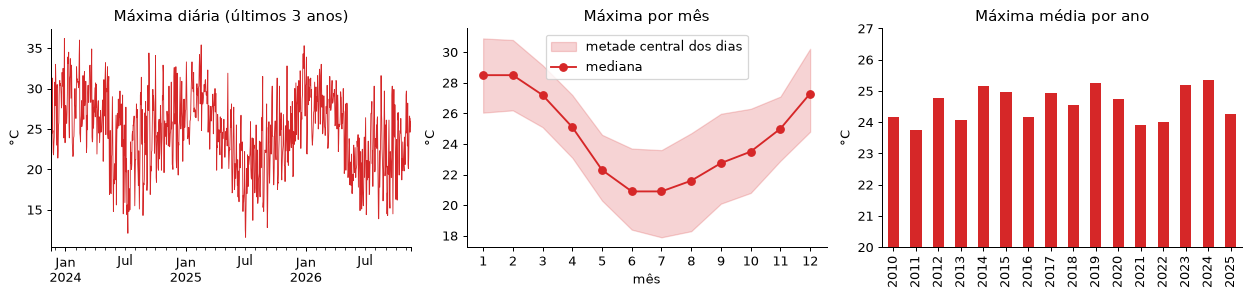

máxima média 24.6 °C, de 9.7 a 37.3 °C


In [4]:
tmax = bruto.set_index("data").tmax
fig, eixos = plt.subplots(1, 3, figsize=(14, 3.4))
tmax.iloc[-3 * 365:].plot(ax=eixos[0], color="tab:red", lw=0.7)
eixos[0].set(title="Máxima diária (últimos 3 anos)", xlabel="", ylabel="°C")
quartis = tmax.groupby(tmax.index.month).quantile([0.25, 0.5, 0.75]).unstack()
eixos[1].fill_between(quartis.index, quartis[0.25], quartis[0.75], color="tab:red", alpha=0.2, label="metade central dos dias")
eixos[1].plot(quartis.index, quartis[0.5], "-o", color="tab:red", label="mediana")
eixos[1].set(title="Máxima por mês", xlabel="mês", ylabel="°C", xticks=range(1, 13))
eixos[1].legend()
tmax.groupby(tmax.index.year).mean().iloc[:-1].plot.bar(ax=eixos[2], color="tab:red")
eixos[2].set(title="Máxima média por ano", xlabel="", ylabel="°C", ylim=(20, 27))
plt.tight_layout()
plt.savefig(config.FIGURAS / "01_tmax.png", bbox_inches="tight")
plt.show()
print(f"máxima média {tmax.mean():.1f} °C, de {tmax.min():.1f} a {tmax.max():.1f} °C")

Há um **ciclo sazonal** forte (mediana de 28,5 °C no verão e 20,9 °C no inverno), que entra no modelo como seno e cosseno do dia do ano.
Mas a sazonalidade sozinha não basta: dentro de um mesmo mês a máxima varia muito de um dia para o outro.

variação de um dia para o outro: média absoluta 2.56 °C
dias com queda de mais de 5 °C: 8.5%  |  com alta de mais de 5 °C: 4.2%


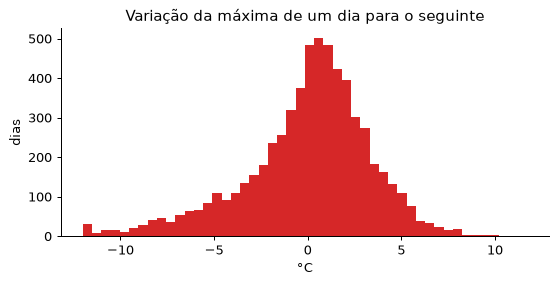

In [5]:
variacao = tmax.diff().dropna()
print(f"variação de um dia para o outro: média absoluta {variacao.abs().mean():.2f} °C")
print(f"dias com queda de mais de 5 °C: {(variacao < -5).mean():.1%}  |  com alta de mais de 5 °C: {(variacao > 5).mean():.1%}")
fig, ax = plt.subplots(figsize=(7, 3))
variacao.clip(-12, 12).plot.hist(bins=48, ax=ax, color="tab:red")
ax.set(title="Variação da máxima de um dia para o seguinte", xlabel="°C", ylabel="dias")
plt.savefig(config.FIGURAS / "01_variacao.png", bbox_inches="tight")
plt.show()

A distribuição tem uma **cauda à esquerda**: quedas bruscas de temperatura, típicas da passagem de **frentes frias**,
são mais intensas que as altas. São os dias mais difíceis de prever.

## Que sinais do dia de hoje ajudam a prever a máxima de amanhã?

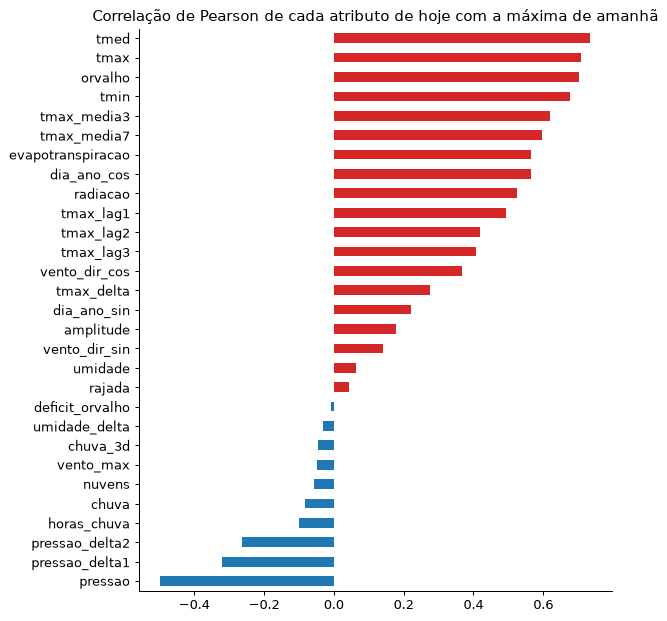

In [6]:
dataset = features.preparar(bruto)
rotulado = dataset[dataset.alvo.notna()]
correlacao = rotulado[features.lista_atributos(dataset) + ["alvo"]].corr()["alvo"].drop("alvo").sort_values()
correlacao.plot.barh(figsize=(7, 7), color=np.where(correlacao > 0, "tab:red", "tab:blue"))
plt.title("Correlação de Pearson de cada atributo de hoje com a máxima de amanhã")
plt.tight_layout()
plt.savefig(config.FIGURAS / "01_correlacoes.png", bbox_inches="tight")
plt.show()

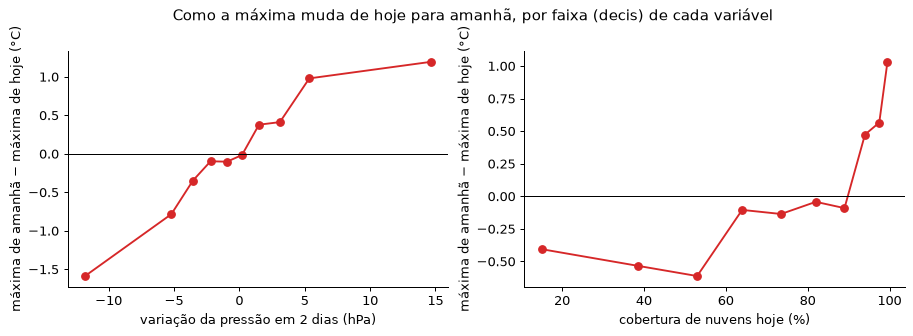

In [7]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 3.4))
mudanca = rotulado.alvo - rotulado.tmax
for ax, (col, nome) in zip(eixos, [("pressao_delta2", "variação da pressão em 2 dias (hPa)"),
                                     ("nuvens", "cobertura de nuvens hoje (%)")]):
    faixas = pd.qcut(rotulado[col], 10, duplicates="drop")
    media = mudanca.groupby(faixas, observed=True).mean()
    ax.plot([i.mid for i in media.index], media.to_numpy(), "-o", color="tab:red")
    ax.axhline(0, color="k", lw=0.8)
    ax.set(xlabel=nome, ylabel="máxima de amanhã − máxima de hoje (°C)")
plt.suptitle("Como a máxima muda de hoje para amanhã, por faixa (decis) de cada variável", y=1.02)
plt.savefig(config.FIGURAS / "01_sinais.png", bbox_inches="tight")
plt.show()

## Conclusões da exploração e tratamentos escolhidos

- **Temperaturas de hoje e dos últimos dias** são o sinal mais forte (correlação alta com o alvo): entram `tmax`, `tmin`,
  `tmed`, os *lags* de 1 a 3 dias, as médias de 3 e 7 dias e a variação `tmax_delta`.
- **Época do ano**: seno e cosseno do dia do ano (31/12 e 01/01 são vizinhos).
- **Mudança de tempo**: pressão **caindo** antecede queda da máxima (frente fria se aproximando, até −1,6 °C em média no decil
  mais baixo) e pressão **subindo** antecede aquecimento; dias muito encobertos tendem a ser seguidos de máximas maiores (o céu
  abre). Entram `pressao_delta1`, `pressao_delta2`, `umidade_delta`, `chuva_3d`.
- **Ar seco** (`deficit_orvalho` = temperatura − ponto de orvalho) e **radiação solar** ajudam a explicar o aquecimento diurno.
- **Direção do vento** é circular: vira seno e cosseno.
- Nenhuma linha é descartada; a padronização é aplicada só no modelo linear (Ridge), que precisa dela.
- Todos os atributos usam apenas o dia t e os anteriores, então **não há vazamento** do futuro: o alvo é a máxima de t+1.